# Capítulo 5: Algoritmos de ordenamiento

---
# Unidad 27: Ordenamiento por Burbuja, Selección e Inserción

## 1. Operación de intercambio (`swap`)

Todos los algoritmos de esta unidad se apoyan en una operación básica: **intercambiar los valores de dos posiciones** dentro de una lista.

In [1]:
def swap(S, x, y):
    """Intercambia los valores de las posiciones x e y de la lista S."""
    temp = S[x]
    S[x] = S[y]
    S[y] = temp

# Prueba
L = [10, 20, 30, 40]
swap(L, 0, 3)
print(L)   # [40, 20, 30, 10]


[40, 20, 30, 10]


> En Python también se puede escribir en una sola línea: `S[x], S[y] = S[y], S[x]`.

## 2. Ordenamiento por Burbuja (*Bubble Sort*)

El ordenamiento por burbuja es un algoritmo de ordenación sencillo que compara pares adyacentes en una lista y los intercambia si están en el orden incorrecto. Repite ese proceso múltiples veces hasta que la lista queda ordenada.

Se llama “burbujear” porque los elementos más grandes (o pequeños, según la variante) van “subiendo” hacia un extremo, como burbujas en un líquido.

**Mecanismo:** compara elementos **adyacentes** e intercambia sus posiciones si están desordenados. En cada pasada, el elemento más grande "burbujea" hacia el extremo derecho de la lista.

Ejemplo con `[5, 1, 4, 2]`:

| Pasada | Estado de la lista |
|---|---|
| Inicio | 5 1 4 2 |
| 1 | 1 4 2 **5** |
| 2 | 1 2 **4 5** |
| 3 | 1 **2 4 5** |

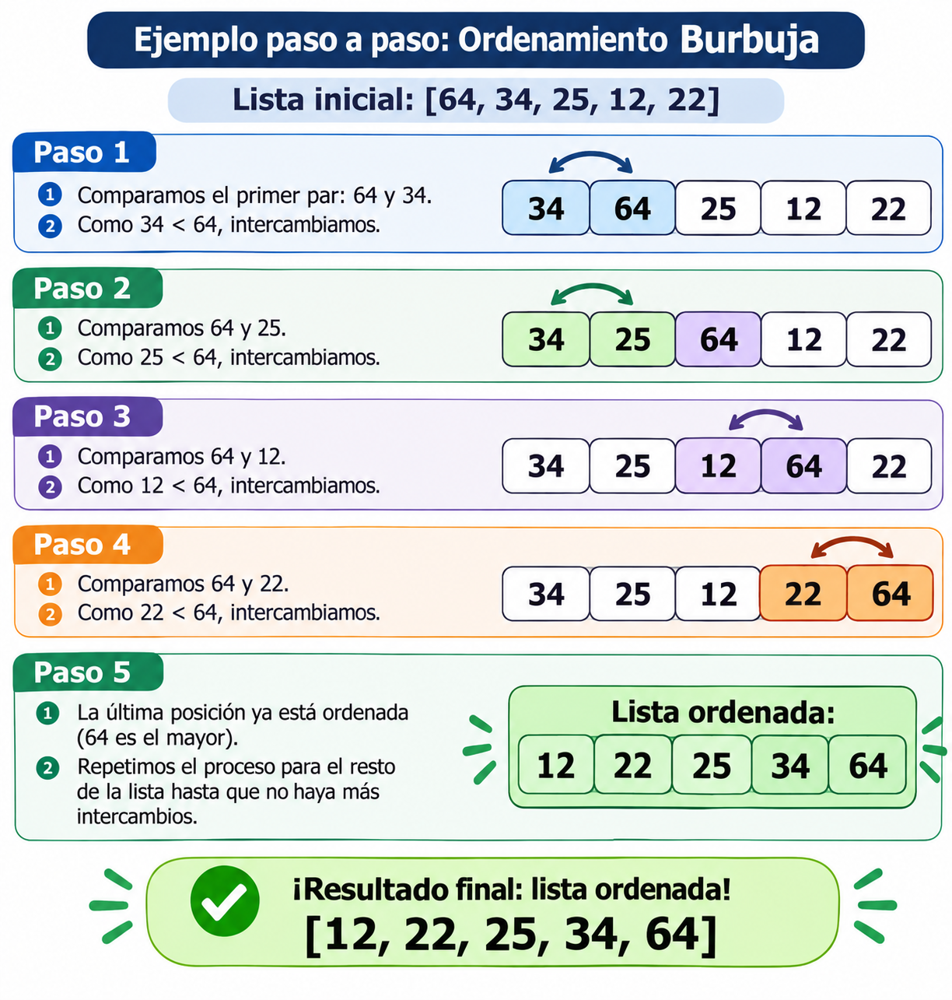

**PSEUDOCODIGO**

In [ ]:
procedimiento burbuja(A) # A seria la lista
  n = longitud(A)
  para i = 0 hasta n-2 hacer
    intercambio = falso
    para j = 0 hasta n-2-i hacer
      si A[j] > A[j+1] entonces
        intercambiar A[j] con A[j+1]
        intercambio = verdadero
      fin si
    fin para
    si intercambio = falso entonces
      salir   // la lista ya está ordenada
    fin si
  fin para
fin procedimiento

**CODIGO**

In [3]:
def ordenamiento_burbuja(lista):
    # Guardamos la longitud de la lista
    longitud = len(lista)

    # Recorremos la lista varias veces (n-1 pasadas)
    for i in range(longitud - 1):
        # Marcamos una bandera para saber si hubo intercambios en esta pasada
        hubo_intercambio = False

        # Recorremos los elementos hasta la parte no ordenada
        for j in range(longitud - 1 - i):
            # Comparamos elementos adyacentes
            if lista[j] > lista[j + 1]:
                # Si están en el orden incorrecto, los intercambiamos
                lista[j], lista[j + 1] = lista[j + 1], lista[j]
                # Indicamos que sí hubo un intercambio
                hubo_intercambio = True

        # Si en toda la pasada no hubo intercambios, la lista ya está ordenada
        if not hubo_intercambio:
            break

    # Devolvemos la lista ya ordenada
    return lista

# Ejecutamos
lista = [5, 1, 4, 2, 8,500,10,0]
print(ordenamiento_burbuja(lista))

[0, 1, 2, 4, 5, 8, 10, 500]


In [4]:
def bubble_sort(lista):
    n = len(lista)
    for i in range(n - 1):
        # Tras cada pasada, los últimos i elementos ya están en su lugar
        for j in range(n - 1 - i):
            if lista[j] > lista[j + 1]:
                swap(lista, j, j + 1)

L = [5, 1, 4, 2, 8, 3]
bubble_sort(L)
print(L)

[1, 2, 3, 4, 5, 8]


## 3. Ordenamiento por Selección (*Selection Sort*)

El ordenamiento por selección es un algoritmo sencillo que funciona de la siguiente manera:

1. Busca el menor elemento de la lista.

2. Lo coloca en la primera posición de la lista.

3. Luego busca el segundo menor elemento y lo coloca en la segunda posición.

4. Se repite este proceso hasta que todos los elementos estén ordenados.

> A diferencia de burbuja, en selección el número de intercambios es menor, porque solo intercambia una vez por cada pasada, aunque hace muchas comparaciones

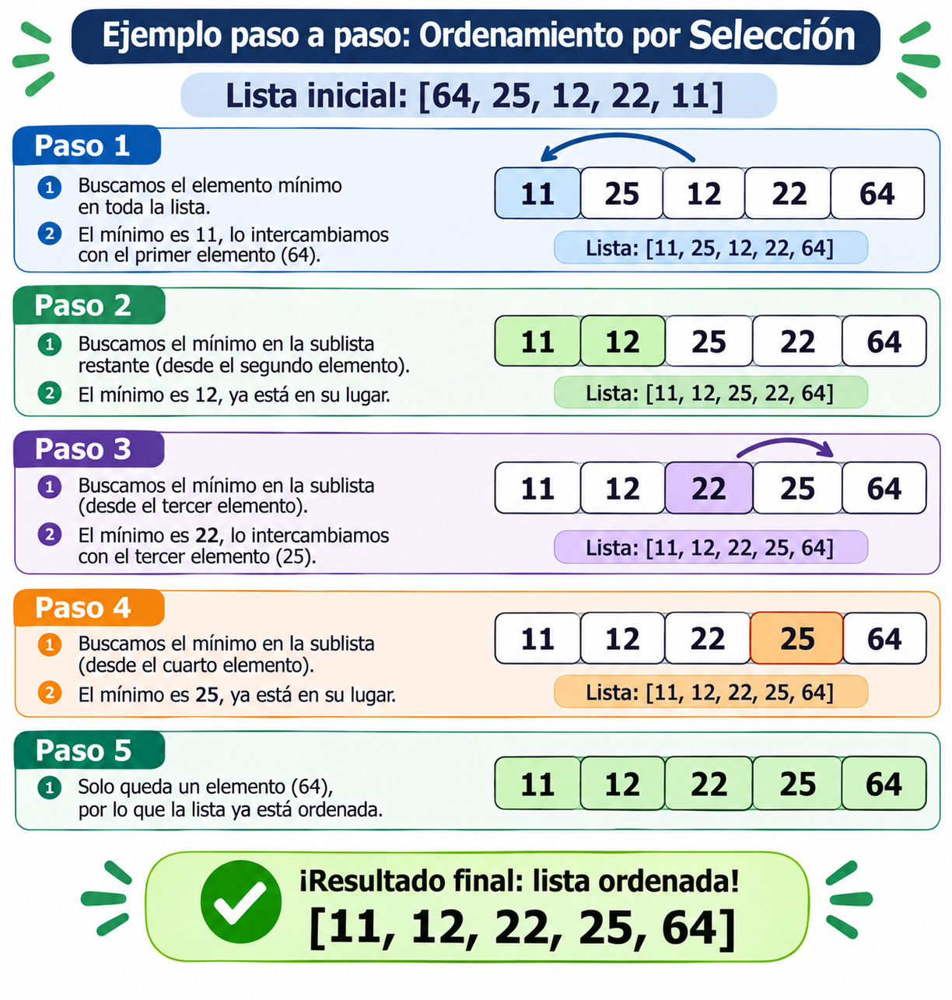

### 3.1 Versión con lista adicional
Se va extrayendo el mínimo de la lista original y se agrega a una lista nueva.

In [ ]:
procedimiento seleccion(A)
  n = longitud(A)
  para i = 0 hasta n-2 hacer
    indice_minimo = i
    para j = i+1 hasta n-1 hacer
      si A[j] < A[indice_minimo] entonces
        indice_minimo = j
      fin si
    fin para
    si indice_minimo != i entonces
      intercambiar A[i] con A[indice_minimo]
    fin si
  fin para
fin procedimiento



---



In [5]:
def ordenamiento_seleccion(lista):
    n = len(lista)
    # Recorremos toda la lista
    for i in range(n - 1):
        # Suponemos que el elemento actual es el mínimo
        indice_minimo = i
        # Buscamos un valor más pequeño en el resto de la lista
        for j in range(i + 1, n):
            if lista[j] < lista[indice_minimo]:
                indice_minimo = j
        # Si encontramos un nuevo mínimo, lo intercambiamos
        if indice_minimo != i:
            temp = lista[i]
            lista[i] = lista[indice_minimo]
            lista[indice_minimo] = temp
    return lista

# Ejemplo
lista = [50, 30, 40, 10, 20]
print(ordenamiento_seleccion(lista))

[10, 20, 30, 40, 50]


In [6]:
def selection_sort_extra(S):
    copia = S[:]          # no modificamos la original
    resultado = []        # lista adicional
    while len(copia) > 0:
        menor = min(copia)
        copia.remove(menor)
        resultado.append(menor)
    return resultado

L = [64, 25, 12, 22, 11]
print(selection_sort_extra(L))
print(L)   # la original no cambia

[11, 12, 22, 25, 64]
[64, 25, 12, 22, 11]


## 4. Ordenamiento por Inserción (*Insertion Sort*)

El ordenamiento por inserción es un algoritmo de ordenamiento que añade elementos de una lista no ordenada a la lista ordenada uno a uno.

Para ello, utiliza una estrategia para encontrar la posición a añadir comparando el elemento a anadir con el resto de la lista ordenada secuencialmente.



---



El ordenamiento por inserción funciona como cuando ordenamos las cartas en la mano:

1. Tomamos una carta de la baraja (un elemento de la lista).

2. La comparamos con las que ya tenemos ordenadas en la mano.

3. La insertamos en el lugar correcto para mantener el orden.

**¿Cuál es su utilidad?**

* Muy eficiente en listas pequeñas o casi ordenadas.

* Fácil de implementar.

* Es estable (mantiene el orden de elementos iguales).

* Se usa como parte de algoritmos más avanzados (ejemplo: Timsort, que es el que usa Python).



---



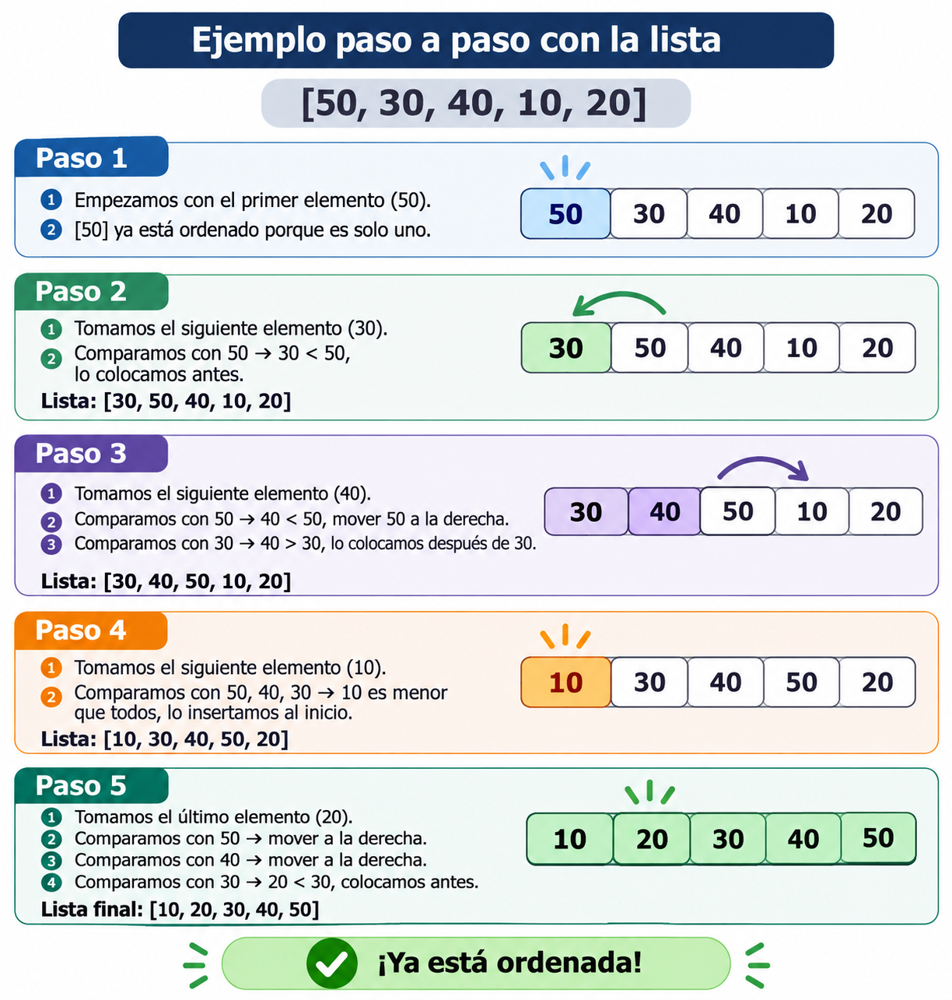

**Mecanismo:** toma **de uno en uno** los elementos de la lista no ordenada e inserta cada uno en la posición correcta dentro de una sublista que se mantiene ordenada (como ordenar cartas en la mano).

In [7]:
def insertion_sort_extra(S):
    resultado = []
    for elemento in S:
        # Buscar la posición donde insertar
        pos = 0
        while pos < len(resultado) and resultado[pos] < elemento:
            pos += 1
        resultado.insert(pos, elemento)
    return resultado

L = [12, 11, 13, 5, 6]
print(insertion_sort_extra(L))

[5, 6, 11, 12, 13]


La sublista ordenada ocupa el inicio de la misma lista; cada nuevo elemento se desplaza hacia la izquierda hasta su lugar.

In [8]:
def insertion_sort(S):
    for i in range(1, len(S)):            # Recorremos desde el segundo elemento
        actual = S[i]                     # Elemento que queremos insertar
        j = i - 1
                                          # Desplazar a la derecha los elementos mayores que 'actual'
        while j >= 0 and S[j] > actual:
            S[j + 1] = S[j]
            j -= 1

        S[j + 1] = actual                 # Insertamos el elemento actual en la posición correcta

L = [12, 11, 13, 5, 6]
insertion_sort(L)
print(L)

[5, 6, 11, 12, 13]


## 5. Aplicación práctica: Anagramas

Dos palabras son **anagramas** si, reordenadas, contienen exactamente las mismas letras (por ejemplo, `roma` y `amor`). Si ordenamos las letras de ambas palabras, el resultado debe ser idéntico.

In [9]:
def son_anagramas(p1, p2):
    # Convertimos a listas de caracteres y las ordenamos con nuestro algoritmo
    l1 = list(p1.lower())
    l2 = list(p2.lower())
    insertion_sort(l1)
    insertion_sort(l2)
    return l1 == l2

print(son_anagramas("roma", "amor"))        # True
print(son_anagramas("python", "typhon"))    # True
print(son_anagramas("hola", "halo"))        # True
print(son_anagramas("casa", "caso"))        # False

print(son_anagramas("I am Lord Voldemort", "Tom Marvolo Riddle"))       # False

True
True
True
False
False


### Versión con la función incorporada `sorted()`

In [10]:
def son_anagramas(palabra1, palabra2):
    palabra1 = palabra1.replace(" ", "").lower()
    palabra2 = palabra2.replace(" ", "").lower()

    return sorted(palabra1) == sorted(palabra2)


print(son_anagramas("I am Lord Voldemort", "Tom Sorvolo Riddle"))  # True

False


### Ejercicios propuestos
1. Modifica `bubble_sort` para que ordene de **mayor a menor**.
2. Modifica `bubble_sort` para que se detenga si en una pasada no hubo ningún intercambio.
3. Haz que `son_anagramas` ignore los espacios (por ejemplo, `"a gentleman"` y `"elegant man"`).

---
# Unidad 28: Ordenamiento por Fusión (*Merge Sort*)

Es el primer algoritmo de alta eficiencia que estudiamos, basado en el paradigma **Divide y Vencerás** (*Divide and Conquer*):

1. **Dividir:** se parte recursivamente la lista en dos sublistas de tamaño equivalente hasta llegar a listas de **un solo elemento** (que ya están ordenadas por definición).
2. **Conquistar / Fusionar:** se combinan (*merge*) progresivamente las sublistas ya ordenadas para reconstruir la lista final.

```
[38, 27, 43, 3]
   /         \
[38, 27]   [43, 3]
 /   \       /   \
[38] [27]  [43]  [3]
 \   /       \   /
[27, 38]   [3, 43]
   \         /
[3, 27, 38, 43]
```

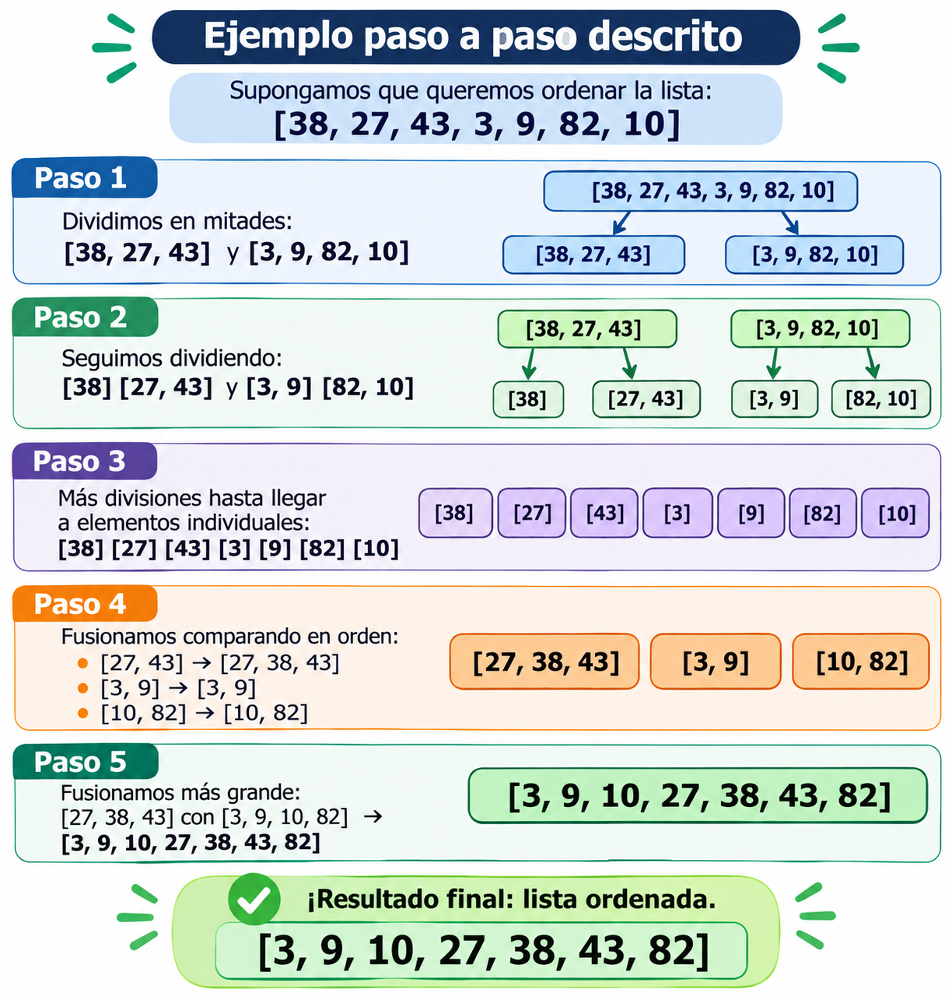

**Ejemplo**

In [11]:
def merge_sort(lista):                              # Define la función merge_sort que recibe una lista y devuelve una lista ordenada.
    if len(lista) <= 1:                             # Caso base: si la lista tiene 0 o 1 elemento ya está ordenada, por eso devolvemos la misma lista tal cual.
        return lista

    medio = len(lista) // 2                         # Calcula el índice medio de la lista usando división entera. Se usa para partir la lista en dos mitades.

    izquierda = merge_sort(lista[:medio])           # Llama recursivamente a merge_sort sobre la porción izquierda (desde 0 hasta medio-1)

    derecha = merge_sort(lista[medio:])
                                                   # Llama recursivamente a merge_sort sobre la porción derecha (desde medio hasta el final).
                                                    # Después de ambas llamadas, 'izquierda' y 'derecha' están ordenadas individualmente.

    return fusionar(izquierda, derecha)
                                                   # Mezcla (merge) las dos sublistas ordenadas y devuelve la lista totalmente ordenada.


def fusionar(izq, der):                              # Definimos la función auxiliar que fusiona dos listas ordenadas en una sola lista ordenada.
    resultado = []                                  # Lista vacía donde iremos acumulando el resultado ordenado.

    i = j = 0                                        # Se inicializan índices para recorrer 'izq' (i) y 'der' (j).

    while i < len(izq) and j < len(der):            # Mientras ambos índices no hayan llegado al final de sus respectivas listas:
        if izq[i] < der[j]:
            resultado.append(izq[i])                 # añadimos el elemento de la izquierda al resultado...
            i += 1                                   # y avanzamos el índice 'i' en la lista izquierda.
        else:
            resultado.append(der[j])                 # añadimos el elemento de la derecha al resultado...
            j += 1                                   # y avanzamos el índice 'j' en la lista derecha.

    resultado.extend(izq[i:])
                                                     # Si se terminó la lista 'der' pero quedan elementos en 'izq', los agregamos todos al final de 'resultado'. extend añade todos los elementos de la sublista.

    resultado.extend(der[j:])
                                                    # Si se terminó la lista 'izq' pero quedan elementos en 'der', los agregamos todos al final de 'resultado'.

    return resultado


print(merge_sort([38, 27, 43, 3, 9, 82, 10]))

[3, 9, 10, 27, 38, 43, 82]


---
# Unidad 29: Ordenamiento Rápido (*Quick Sort*)

Es el algoritmo de ordenamiento ***in-situ*** más utilizado en la práctica, también basado en **Divide y Vencerás**.

## 1. Conceptos clave

- **Pivote (*pivot*):** elemento seleccionado como referencia.
- **Partición (*partition*):** reorganiza la lista para dejar **todos los elementos menores que el pivote a su izquierda** y **todos los mayores a su derecha**. El pivote queda en su posición definitiva.

Luego se repite el proceso recursivamente en cada lado.

```
[7, 2, 9, 4, 3, 8]      pivote = 7
[3, 2, 4] 7 [9, 8]      tras la partición
```

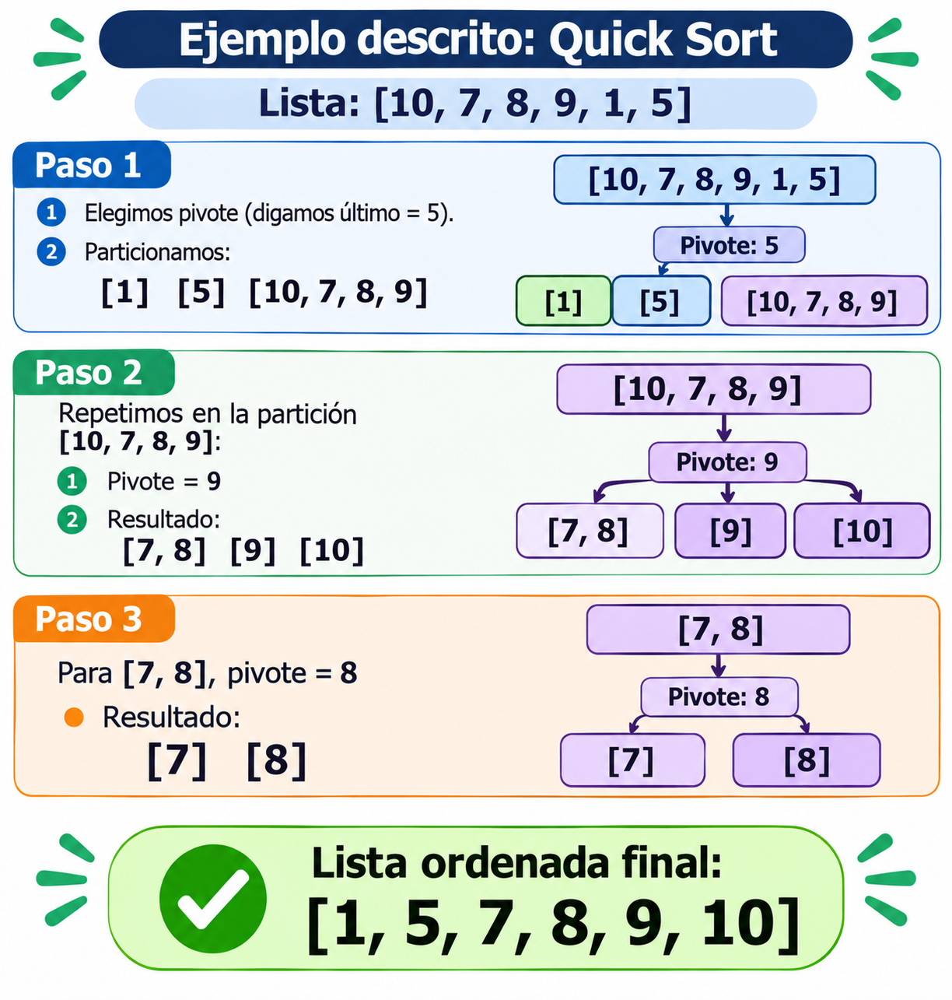

In [12]:
def quick_sort(lista):
    # Define la función quick_sort que recibe una lista y devuelve la lista ordenada.

    if len(lista) <= 1:
        # Caso base: si la lista tiene 0 o 1 elemento ya está ordenada.
        return lista

    pivote = lista[-1]                                 # último elemento como pivote. Elegimos el último elemento de la lista como "pivote" para dividir la lista.

    menores = [x for x in lista[:-1] if x <= pivote]
                                                       # Crea una lista con todos los elementos de la lista original (menos el pivote) que son menores o iguales al pivote.

    mayores = [x for x in lista[:-1] if x > pivote]
                                                       # Crea una lista con todos los elementos de la lista original (menos el pivote)

    return quick_sort(menores) + [pivote] + quick_sort(mayores)
    # Llama recursivamente a quick_sort sobre la lista de menores y sobre la lista de mayores,
    # y luego concatena: lista ordenada de menores + pivote + lista ordenada de mayores. Esto devuelve la lista completamente ordenada.

print(quick_sort([10, 7, 8, 9, 1, 5]))

[1, 5, 7, 8, 9, 10]


---
# Resumen

| Algoritmo | Idea principal | ¿In-situ? |
|---|---|---|
| Burbuja | Comparar adyacentes e intercambiar | Sí |
| Selección | Buscar el menor y colocarlo al inicio | Sí (o con lista extra) |
| Inserción | Insertar cada elemento en la sublista ordenada | Sí (o con lista extra) |
| Fusión (*Merge Sort*) | Dividir en mitades y fusionar ordenadas | `mergesort1` no, `mergesort2` usa solo una lista temporal |
| Rápido (*Quick Sort*) | Elegir pivote y particionar | Sí |